# 05: Comprehensive Validation Report — Measured Tiers and Methods

Assembles per-vendor validation tables from the **measured** JSON exports in
`reports/comparison/<vendor>/`. No circuit is re-simulated here and no number
is invented.

Coverage: **Tier-2**, **Tier-3 v1**, **Tier-3 SIMPLIS**, **UROM C0**,
**UROM ANN**, **T4**, **T4_ANN** for all four configured vendors. Static
errors, DPT Vds/Id waveform RMSE, G4 pass counts and measured speed/net
values are read verbatim from the JSON records. Missing measurements remain
`not available` — for example Tier-2 has no recorded DPT waveform gate and
the T4 waveform gate is retired by design.

The final section plots the measured summary and writes
`reports/validation_report.html`.


In [1]:
import sys, os, json, io, base64
from pathlib import Path
REPO_ROOT = Path.cwd()
if REPO_ROOT.name == 'notebooks':
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT)); os.chdir(REPO_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from common.plotting import setup_style

VENDORS = ('irfs7730pbf', 'csd16412q5a', 'epc2216', 'cpm2-1200')
METHODS = ('Tier-2', 'Tier-3 v1', 'Tier-3 SIMPLIS', 'UROM C0',
           'UROM ANN', 'T4', 'T4_ANN')
CMP = REPO_ROOT / 'reports' / 'comparison'
OUT_HTML = REPO_ROOT / 'reports' / 'validation_report.html'
setup_style()


In [2]:
def load_json(path):
    p = Path(path)
    if not p.exists():
        return None
    return json.loads(p.read_text(encoding='utf-8'))


def disp(v, pct=False):
    if v is None:
        return 'not available'
    try:
        f = float(v)
    except (TypeError, ValueError):
        return str(v)
    if not np.isfinite(f):
        return 'not available'
    return f'{f:+.2f}%' if pct else f'{f:.4g}'


def fnum(v, nd=3):
    if v is None:
        return 'not available'
    try:
        f = float(v)
    except (TypeError, ValueError):
        return str(v)
    return f'{f:.{nd}f}' if np.isfinite(f) else 'not available'


def wave_rmse(obj, *keys):
    if obj is None:
        return None, None
    for k in keys:
        if not isinstance(obj, dict) or k not in obj:
            return None, None
        obj = obj[k]
    if not isinstance(obj, dict):
        return None, None
    return obj.get('vds_rel_rmse_pct'), obj.get('id_rel_rmse_pct')


def mean_finite(vals):
    vals = [float(v) for v in vals
            if v is not None and np.isfinite(float(v))]
    return float(np.mean(vals)) if vals else None


def g4_counts(gate):
    if not gate:
        return None, None, {}
    rows = gate.get('detail', {}).get('rows', {})
    measured = {k: r for k, r in rows.items()
                if r.get('status') == 'measured'}
    passed = sum(1 for r in measured.values() if r.get('pass'))
    return passed, len(measured), measured


def kv_table(rows):
    return pd.DataFrame(rows, columns=['quantity', 'value'])


CAVEAT = ('Manufacturer datasheets were checked against extracted currents at the '
          'rated gate drive: IRFS7730PBF 246 A continuous / 984 A pulsed vs 1671 A '
          'extracted at Vgs=10 V; CSD16412Q5A 52 A / 91 A vs 305 A; EPC2216 3.4 A / '
          '28 A vs 61.7 A at Vgs=6 V; CPM2-1200 81 A / 200 A vs 342 A at Vgs=20 V. '
          'These excesses are properties of the vendor subcircuits (VM-04/VM-06). '
          'Matching the vendor golden is not the same as matching the datasheet; '
          'fidelity claims against the vendor must not be read as physical device '
          'ratings.')

METHOD_COLORS = dict(zip(METHODS, plt.cm.tab10.colors))


In [3]:
sections, summary_rows = [], []
speed_bench = load_json(CMP / 'speedup_benchmark.json') or {}

for vendor in VENDORS:
    base = CMP / vendor
    ep = load_json(base / 'endpoint_comparison.json')
    fs = load_json(base / 'full_sweep_comparison.json')
    d2 = load_json(base / 'dpt_metrics.json')
    d3 = load_json(base / 'tier3_validation.json')
    d3s = load_json(base / 'tier3_validation_simplis.json')
    u0 = load_json(base / 'unified_validation.json')
    ua = load_json(base / 'unified_ann_trap-default.json')
    t4 = load_json(base / 'tier4_validation.json')
    t4a = load_json(base / 'tier4_validation_ann.json')

    # ---- Tier-2 ---------------------------------------------------------
    t2_end = pd.DataFrame([{
        'Vgs [V]': r['vgs_v'], 'golden [A]': disp(r['golden_a']),
        'Tier-2 [A]': disp(r['tier2_a']),
        'rel err': disp(r['rel_err_pct'], pct=True)} for r in ep])
    t2_sweep = pd.DataFrame([{
        'curve': r['curve'], 'points': r['points'],
        'rel RMSE': disp(r['rel_rmse_pct'], pct=True),
        'peak RMSE': disp(r['peak_rmse_pct'], pct=True),
        'max rel err': disp(r['max_rel_pct'], pct=True),
        'R^2': disp(r['r_squared']), 'pass': r['pass']} for r in fs])
    t2_static = mean_finite([r['rel_rmse_pct'] for r in fs])
    t2_case = (speed_bench.get('vendors', {}).get(vendor, {})
               .get('long_100ns', {}))
    t2_speed = t2_case.get('solver_speedup')

    # ---- Tier-3 v1 (TPWL) ----------------------------------------------
    fit3 = d3['function_fit']
    t3_static = fit3['emitted_static_curve_rmse_rel'] * 100.0
    t3_vds, t3_id = wave_rmse(d3, 'dpt_run', 'waveform')
    t3_forced_speed = d3.get('runtime', {}).get('solver_speedup')

    # ---- Tier-3 SIMPLIS ------------------------------------------------
    fit3s = d3s['function_fit']
    t3s_static = fit3s['emitted_static_curve_rmse_rel']  # already percent
    t3s_vds, t3s_id = wave_rmse(d3s, 'dpt_waveform')
    t3s_sp = d3s.get('speed_adaptive_20', {})
    t3s_speed = t3s_sp.get('solver_speedup')
    t3s_wall = t3s_sp.get('wall_speedup')

    # ---- UROM C0 / ANN --------------------------------------------------
    u0_static = u0.get('static', {}).get('full_sweep_rel_rmse_pct')
    u0_vds, u0_id = wave_rmse(u0, 'dpt_waveform')
    u0_gate = u0.get('gates', {}).get('G4_timing_energy')
    u0_pass, u0_total, _ = g4_counts(u0_gate)
    u0_sp = u0.get('speed_adaptive_20', {})
    u0_speed = u0_sp.get('solver_speedup')
    u0_net = u0_sp.get('net_solver_speedup')

    ua_static = ua.get('static', {}).get('full_sweep_rel_rmse_pct')
    ua_vds, ua_id = wave_rmse(ua, 'dpt_waveform')
    ua_gate = ua.get('gates', {}).get('G4_timing_energy')
    ua_pass, ua_total, _ = g4_counts(ua_gate)
    ua_sp = ua.get('speed_adaptive_20', {})
    ua_speed = ua_sp.get('solver_speedup')
    ua_net = ua_sp.get('net_solver_speedup')

    # ---- T4 / T4_ANN ----------------------------------------------------
    t4_sp = t4.get('speedup', {})
    t4_speed = t4_sp.get('solver_speedup')
    t4a_static = t4a.get('ann_static_rms_rel')
    t4a_static_pct = t4a_static * 100.0 if t4a_static is not None else None
    t4a_vds, t4a_id = wave_rmse(t4a, 'dpt_waveform')
    t4a_sp = t4a.get('speedup', {})
    t4a_speed = t4a_sp.get('solver_speedup')
    t4a_net = t4a_sp.get('net_solver_speedup')
    t4a_200 = t4a.get('speedup_200_pulse', {})

    methods = [
        dict(name='Tier-2', static=t2_static, dpt_vds=None, dpt_id=None,
             g4=(None, None), speed=t2_speed, net=None,
             basis='long_100ns solver vs golden',
             note='DPT waveform not recorded; speed is the recorded ROM bench',
             source='full_sweep_comparison.json + speedup_benchmark.json'),
        dict(name='Tier-3 v1', static=t3_static, dpt_vds=t3_vds,
             dpt_id=t3_id, g4=(None, None), speed=None, net=None,
             basis='forced 2 ns fidelity control only',
             note=f'forced-control solver ratio {fnum(t3_forced_speed)}; not a speed claim',
             source='tier3_validation.json'),
        dict(name='Tier-3 SIMPLIS', static=t3s_static, dpt_vds=t3s_vds,
             dpt_id=t3s_id, g4=(None, None), speed=t3s_speed, net=None,
             basis='20-pulse adaptive solver',
             note=f'wall ratio {fnum(t3s_wall)}; selected charge=tables',
             source='tier3_validation_simplis.json'),
        dict(name='UROM C0', static=u0_static, dpt_vds=u0_vds,
             dpt_id=u0_id, g4=(u0_pass, u0_total), speed=u0_speed,
             net=u0_net, basis='20-pulse adaptive solver',
             note='G4 recorded; net value not recorded',
             source='unified_validation.json'),
        dict(name='UROM ANN', static=ua_static, dpt_vds=ua_vds,
             dpt_id=ua_id, g4=(ua_pass, ua_total), speed=ua_speed,
             net=ua_net, basis='20-pulse adaptive net' if ua_net else
             '20-pulse adaptive solver',
             note='G4 recorded', source='unified_ann_trap-default.json'),
        dict(name='T4', static=None, dpt_vds=None, dpt_id=None,
             g4=(None, None), speed=t4_speed, net=None,
             basis=f"{t4_sp.get('case', 'recorded')} solver",
             note='DPT waveform gate retired; energy comparison is LUT '
                  'source self-consistency, not independent',
             source='tier4_validation.json'),
        dict(name='T4_ANN', static=t4a_static_pct, dpt_vds=t4a_vds,
             dpt_id=t4a_id, g4=(None, None), speed=t4a_speed,
             net=t4a_net,
             basis=(f"{t4a_sp.get('case', 'recorded')} "
                    f"{'net' if t4a_net else 'solver'}"),
             note=(f"200-pulse net {fnum(t4a_200.get('net_solver_speedup'))}; "
                   f"solver {fnum(t4a_200.get('solver_speedup'))}"),
             source='tier4_validation_ann.json'),
    ]

    # ---- detailed per-vendor tables -------------------------------------
    t3_static_df = kv_table([
        ('Tier-3 static fit rel RMSE', disp(fit3['static_curve_rmse_rel'] * 100, pct=True)),
        ('Tier-3 emitted static rel RMSE', disp(t3_static, pct=True)),
        ('Tier-3 held-out Id rel RMSE', disp(fit3['heldout_id_rmse_rel'] * 100, pct=True)),
        ('Tier-3 held-out Qg rel RMSE', disp(fit3['heldout_qg_rmse_rel'] * 100, pct=True)),
        ('static samples', fit3['static_samples']),
    ])
    t3_dpt = pd.DataFrame([{
        'metric': k, 'golden': disp(c['golden']),
        'Tier-2': disp(c['tier2']), 'Tier-3': disp(c['tier3']),
        'T2 err': disp(c['tier2_rel_err_pct'], pct=True),
        'T3 err': disp(c['tier3_rel_err_pct'], pct=True)}
        for k, c in d3['dpt_comparison'].items()])
    dr, wf, rt = d3['dpt_run'], d3['dpt_run']['waveform'], d3['runtime']
    t3_run = kv_table([
        ('DPT completed', dr['completed']),
        ('golden trace points', dr['golden_trace_points']),
        ('Tier-3 trace points', dr['trace_points']),
        ('Tier-3 iterations', dr['iterations']),
        ('DPT Vds rel RMSE', disp(wf['vds_rel_rmse_pct'], pct=True)),
        ('DPT Id rel RMSE', disp(wf['id_rel_rmse_pct'], pct=True)),
        ('golden solver elapsed [s]', rt['golden']['solver_elapsed_s']),
        ('Tier-3 solver elapsed [s]', rt['tier3']['solver_elapsed_s']),
        ('forced-control solver ratio', disp(rt['solver_speedup'])),
        ('Tier-2 golden failure', d2.get('golden_failure') or 'none'),
    ])

    t3s_dpt = pd.DataFrame([{
        'metric': k, 'golden': disp(c['golden']),
        'Tier-3 SIMPLIS': disp(c['tier3']),
        'rel err': disp(c['tier3_rel_err_pct'], pct=True)}
        for k, c in d3s['dpt_comparison'].items()])
    t3s_static_df = kv_table([
        ('emitted static rel RMSE', disp(t3s_static, pct=True)),
        ('Tier-2 recorded mean rel RMSE', disp(fit3s['tier2_recorded_mean_rel_rmse_pct'], pct=True)),
        ('static delta vs Tier-2 [pp]', disp(fit3s['static_delta_pp_vs_tier2'])),
        ('static scope', fit3s['static_rmse_scope']),
        ('charge candidate', d3s['algorithm'].get('charge_candidate_selected')),
        ('channel candidate', d3s['algorithm'].get('channel_candidate_selected')),
        ('20-pulse solver speedup', disp(t3s_speed)),
        ('20-pulse wall speedup', disp(t3s_wall)),
        ('DPT Vds rel RMSE', disp(t3s_vds, pct=True)),
        ('DPT Id rel RMSE', disp(t3s_id, pct=True)),
    ])

    def urom_tables(u):
        gate_df = pd.DataFrame([{
            'gate': k, 'pass': v.get('pass'), 'status': v.get('status')}
            for k, v in u['gates'].items() if isinstance(v, dict)])
        sp = u.get('speed_adaptive_20', {})
        p, t, _ = g4_counts(u.get('gates', {}).get('G4_timing_energy'))
        summary_tbl = kv_table([
            ('static full-sweep rel RMSE', disp(u.get('static', {}).get('full_sweep_rel_rmse_pct'), pct=True)),
            ('DPT Vds rel RMSE', disp(wave_rmse(u, 'dpt_waveform')[0], pct=True)),
            ('DPT Id rel RMSE', disp(wave_rmse(u, 'dpt_waveform')[1], pct=True)),
            ('G4 pass count', f'{p}/{t}' if t else 'not available'),
            ('20-pulse solver speedup', disp(sp.get('solver_speedup'))),
            ('20-pulse wall speedup', disp(sp.get('wall_speedup'))),
            ('20-pulse net speedup', disp(sp.get('net_solver_speedup'))),
            ('overall verdict', u.get('overall_verdict')),
        ])
        return gate_df, summary_tbl

    u0_gates, u0_summary = urom_tables(u0)
    ua_gates, ua_summary = urom_tables(ua)

    t4_energy = t4.get('energy_comparison', {})
    t4_tbl = kv_table([
        ('emission status', t4.get('emission', {}).get('status')),
        ('DPT completed', t4.get('dpt_run', {}).get('completed')),
        ('DPT trace points', t4.get('dpt_run', {}).get('trace_points')),
        ('E_on rel error [%]', disp(t4_energy.get('e_on_uj', {}).get('rel_error_pct'))),
        ('E_off rel error [%]', disp(t4_energy.get('e_off_uj', {}).get('rel_error_pct'))),
        ('energy status', t4_energy.get('e_on_uj', {}).get('status')),
        ('energy independent', t4_energy.get('e_on_uj', {}).get('independent_energy_gate')),
        ('converter', 'not configured' if t4.get('converter') is None else 'configured'),
        ('speed case', t4_sp.get('case')),
        ('solver speedup', disp(t4_speed)),
        ('wall speedup', disp(t4_sp.get('wall_speedup'))),
    ])
    t4a_dpt = pd.DataFrame([{
        'metric': k, 'golden': disp(c['golden']),
        'T4_ANN': disp(c['tier4_ann']),
        'rel err': disp(c['rel_err_pct'], pct=True)}
        for k, c in t4a['dpt_comparison'].items()])
    t4a_tbl = kv_table([
        ('static RMS rel error', disp(t4a_static_pct, pct=True)),
        ('DPT Vds rel RMSE', disp(t4a_vds, pct=True)),
        ('DPT Id rel RMSE', disp(t4a_id, pct=True)),
        ('20-pulse case', t4a_sp.get('case')),
        ('20-pulse solver speedup', disp(t4a_speed)),
        ('20-pulse net speedup', disp(t4a_net)),
        ('200-pulse solver speedup', disp(t4a_200.get('solver_speedup'))),
        ('200-pulse net speedup', disp(t4a_200.get('net_solver_speedup'))),
    ])

    print(f'\n===== {vendor} : Tier-2 endpoint comparison ====='); display(t2_end)
    print(f'----- {vendor} : Tier-2 full-sweep fit -----'); display(t2_sweep)
    print(f'----- {vendor} : Tier-3 v1 static fit -----'); display(t3_static_df)
    print(f'----- {vendor} : DPT timing / energy (golden vs T2 vs T3) -----'); display(t3_dpt)
    print(f'----- {vendor} : Tier-3 v1 DPT run / runtime -----'); display(t3_run)
    print(f'----- {vendor} : Tier-3 SIMPLIS static / DPT -----'); display(t3s_static_df)
    print(f'----- {vendor} : Tier-3 SIMPLIS DPT timing / energy -----'); display(t3s_dpt)
    print(f'----- {vendor} : UROM C0 gates -----'); display(u0_gates)
    print(f'----- {vendor} : UROM C0 measured summary -----'); display(u0_summary)
    print(f'----- {vendor} : UROM ANN gates -----'); display(ua_gates)
    print(f'----- {vendor} : UROM ANN measured summary -----'); display(ua_summary)
    print(f'----- {vendor} : T4 measured summary -----'); display(t4_tbl)
    print(f'----- {vendor} : T4_ANN DPT timing / energy -----'); display(t4a_dpt)
    print(f'----- {vendor} : T4_ANN measured summary -----'); display(t4a_tbl)

    detail_html = ''.join([
        f'<h2>{vendor}</h2>',
        '<h3>Tier-2 endpoint comparison</h3>' + t2_end.to_html(index=False),
        '<h3>Tier-2 full-sweep fit</h3>' + t2_sweep.to_html(index=False),
        '<h3>Tier-3 v1 static fit</h3>' + t3_static_df.to_html(index=False),
        '<h3>DPT timing / energy (golden vs T2 vs T3)</h3>' + t3_dpt.to_html(index=False),
        '<h3>Tier-3 v1 DPT run / runtime</h3>' + t3_run.to_html(index=False),
        '<h3>Tier-3 SIMPLIS static / DPT</h3>' + t3s_static_df.to_html(index=False),
        '<h3>Tier-3 SIMPLIS DPT timing / energy</h3>' + t3s_dpt.to_html(index=False),
        '<h3>UROM C0 gates</h3>' + u0_gates.to_html(index=False),
        '<h3>UROM C0 measured summary</h3>' + u0_summary.to_html(index=False),
        '<h3>UROM ANN gates</h3>' + ua_gates.to_html(index=False),
        '<h3>UROM ANN measured summary</h3>' + ua_summary.to_html(index=False),
        '<h3>T4 measured summary</h3>' + t4_tbl.to_html(index=False),
        '<h3>T4_ANN DPT timing / energy</h3>' + t4a_dpt.to_html(index=False),
        '<h3>T4_ANN measured summary</h3>' + t4a_tbl.to_html(index=False),
    ])
    sections.append(detail_html)

    for m in methods:
        p, t = m['g4']
        summary_rows.append({
            'vendor': vendor, 'method': m['name'],
            'static_rel_rmse_pct': m['static'],
            'dpt_vds_rmse_pct': m['dpt_vds'],
            'dpt_id_rmse_pct': m['dpt_id'],
            'g4_pass_n': p, 'g4_total_n': t,
            'speed_solver': m['speed'], 'speed_net': m['net'],
            'speed_basis': m['basis'], 'note': m['note'],
            'source': m['source']})

summary = pd.DataFrame(summary_rows)
print('\nCollected measured rows:', len(summary),
      '| vendors:', len(VENDORS), '| methods:', len(METHODS))



===== irfs7730pbf : Tier-2 endpoint comparison =====


,Vgs [V],golden [A],Tier-2 [A],rel err
0,3.0,2.021e-07,2.021e-07,+0.00%
1,4.5,7.159,6.875,+3.96%
2,6.0,340.1,327.5,+3.72%
3,8.0,975.1,940.1,+3.59%
4,10.0,1671,1620,+3.08%


----- irfs7730pbf : Tier-2 full-sweep fit -----


,curve,points,rel RMSE,peak RMSE,max rel err,R^2,pass
0,Vgs = 3 V,101,+10.20%,+10.20%,+14.72%,0.8752,False
1,Vgs = 4.5 V,101,+14.66%,+14.66%,+53.07%,-0.316,False
2,Vgs = 6 V,101,+4.67%,+4.67%,+9.51%,0.9413,True
3,Vgs = 8 V,101,+3.08%,+3.08%,+6.94%,0.9861,True
4,Vgs = 10 V,101,+3.67%,+3.67%,+7.06%,0.985,True


----- irfs7730pbf : Tier-3 v1 static fit -----


,quantity,value
0,Tier-3 static fit rel RMSE,+216.23%
1,Tier-3 emitted static rel RMSE,+1.70%
2,Tier-3 held-out Id rel RMSE,+5101666549.45%
3,Tier-3 held-out Qg rel RMSE,+11.25%
4,static samples,505


... (104 outputs left out)

----- cpm2-1200 : T4_ANN measured summary -----


,quantity,value
0,static RMS rel error,+0.14%
1,DPT Vds rel RMSE,+2.03%
2,DPT Id rel RMSE,+2.10%
3,20-pulse case,long_adaptive
4,20-pulse solver speedup,1.116
5,20-pulse net speedup,1.154
6,200-pulse solver speedup,1.313
7,200-pulse net speedup,1.343



Collected measured rows:

 28 | vendors: 4 | methods: 7


## Sources and caveats

All values are read from
`reports/comparison/<vendor>/{endpoint_comparison,full_sweep_comparison,
dpt_metrics,tier3_validation,tier3_validation_simplis,unified_validation,
unified_ann_trap-default,tier4_validation,tier4_validation_ann}.json` and the
global `speedup_benchmark.json`. The `T2 static mean rel RMSE` is the
arithmetic mean of the measured per-curve `rel_rmse_pct` values in
`full_sweep_comparison.json`.

Scale conventions are kept source-specific and are **not** silently
normalised: Tier-3 v1 and T4_ANN store static RMSE as a fraction, while
Tier-3 SIMPLIS and the UROM records store percent. The notebook converts to
percent and labels the source.

Static estimators are also source-native: Tier-2 is the arithmetic mean of
the per-curve `rel_rmse_pct`; Tier-3 v1/SIMPLIS and UROM use their emitted
full-sweep relative RMSE; T4_ANN reports its `ann_static_rms_rel`. The
summary column is therefore called `static error [%]`, not "RMSE", so a
reader does not infer one common estimator.

Not every tier has every measurement:

- Tier-2 records endpoint/full-sweep static fit, DPT timing/energy and a
  recorded ROM speed bench. It has **no recorded DPT Vds/Id waveform gate**
  and no G4 gate.
- Tier-3 v1 has a recorded DPT waveform, but its speed run is a **forced 2 ns
  fidelity control**, not a speed claim, so it is left `not available` in the
  speed plot.
- Tier-3 SIMPLIS has static, DPT waveform, and a 20-pulse adaptive speed
  record; it has no G4 gate record.
- UROM C0/ANN are the only methods with recorded G4 timing/energy pass
  counts.
- T4 retires the waveform gate by design; its energy comparison is a LUT
  source self-consistency check (0.00 % by construction), not independent.
- T4_ANN has a recorded DPT waveform and 20-/200-pulse speed records.

All measured solver time ratios below 1.0 are slowdowns; no speedup is
claimed from a forced-control or non-independent record.

Manufacturer datasheets were checked against extracted currents at the rated gate drive: IRFS7730PBF 246 A continuous / 984 A pulsed vs 1671 A extracted at Vgs=10 V; CSD16412Q5A 52 A / 91 A vs 305 A; EPC2216 3.4 A / 28 A vs 61.7 A at Vgs=6 V; CPM2-1200 81 A / 200 A vs 342 A at Vgs=20 V. These excesses are properties of the vendor subcircuits (VM-04/VM-06). Matching the vendor golden is not the same as matching the datasheet; fidelity claims against the vendor must not be read as physical device ratings.

Consolidated measured validation summary (all tiers/methods with records)


,vendor,method,static error [%],DPT Vds RMSE [%],DPT Id RMSE [%],solver speedup,net speedup,speed_basis,g4
0,irfs7730pbf,Tier-2,7.256,not available,not available,1.008,not available,long_100ns solver vs golden,not available
1,irfs7730pbf,Tier-3 v1,1.699,12.698,10.958,not available,not available,forced 2 ns fidelity control only,not available
2,irfs7730pbf,Tier-3 SIMPLIS,7.115,6.159,6.183,0.990,not available,20-pulse adaptive solver,not available
3,irfs7730pbf,UROM C0,7.160,10.000,9.008,0.985,not available,20-pulse adaptive solver,0/6
4,irfs7730pbf,UROM ANN,2.067,0.417,0.558,0.962,0.950,20-pulse adaptive net,5/6
5,irfs7730pbf,T4,not available,not available,not available,1.221,not available,long_adaptive solver,not available
6,irfs7730pbf,T4_ANN,0.125,0.471,0.656,0.962,0.951,long_adaptive net,not available
7,csd16412q5a,Tier-2,8.558,not available,not available,4.885,not available,long_100ns solver vs golden,not available
8,csd16412q5a,Tier-3 v1,2.153,2.925,4.896,not available,not available,forced 2 ns fidelity control only,not available
9,csd16412q5a,Tier-3 SIMPLIS,8.486,4.044,4.879,5.593,not available,20-pulse adaptive solver,not available


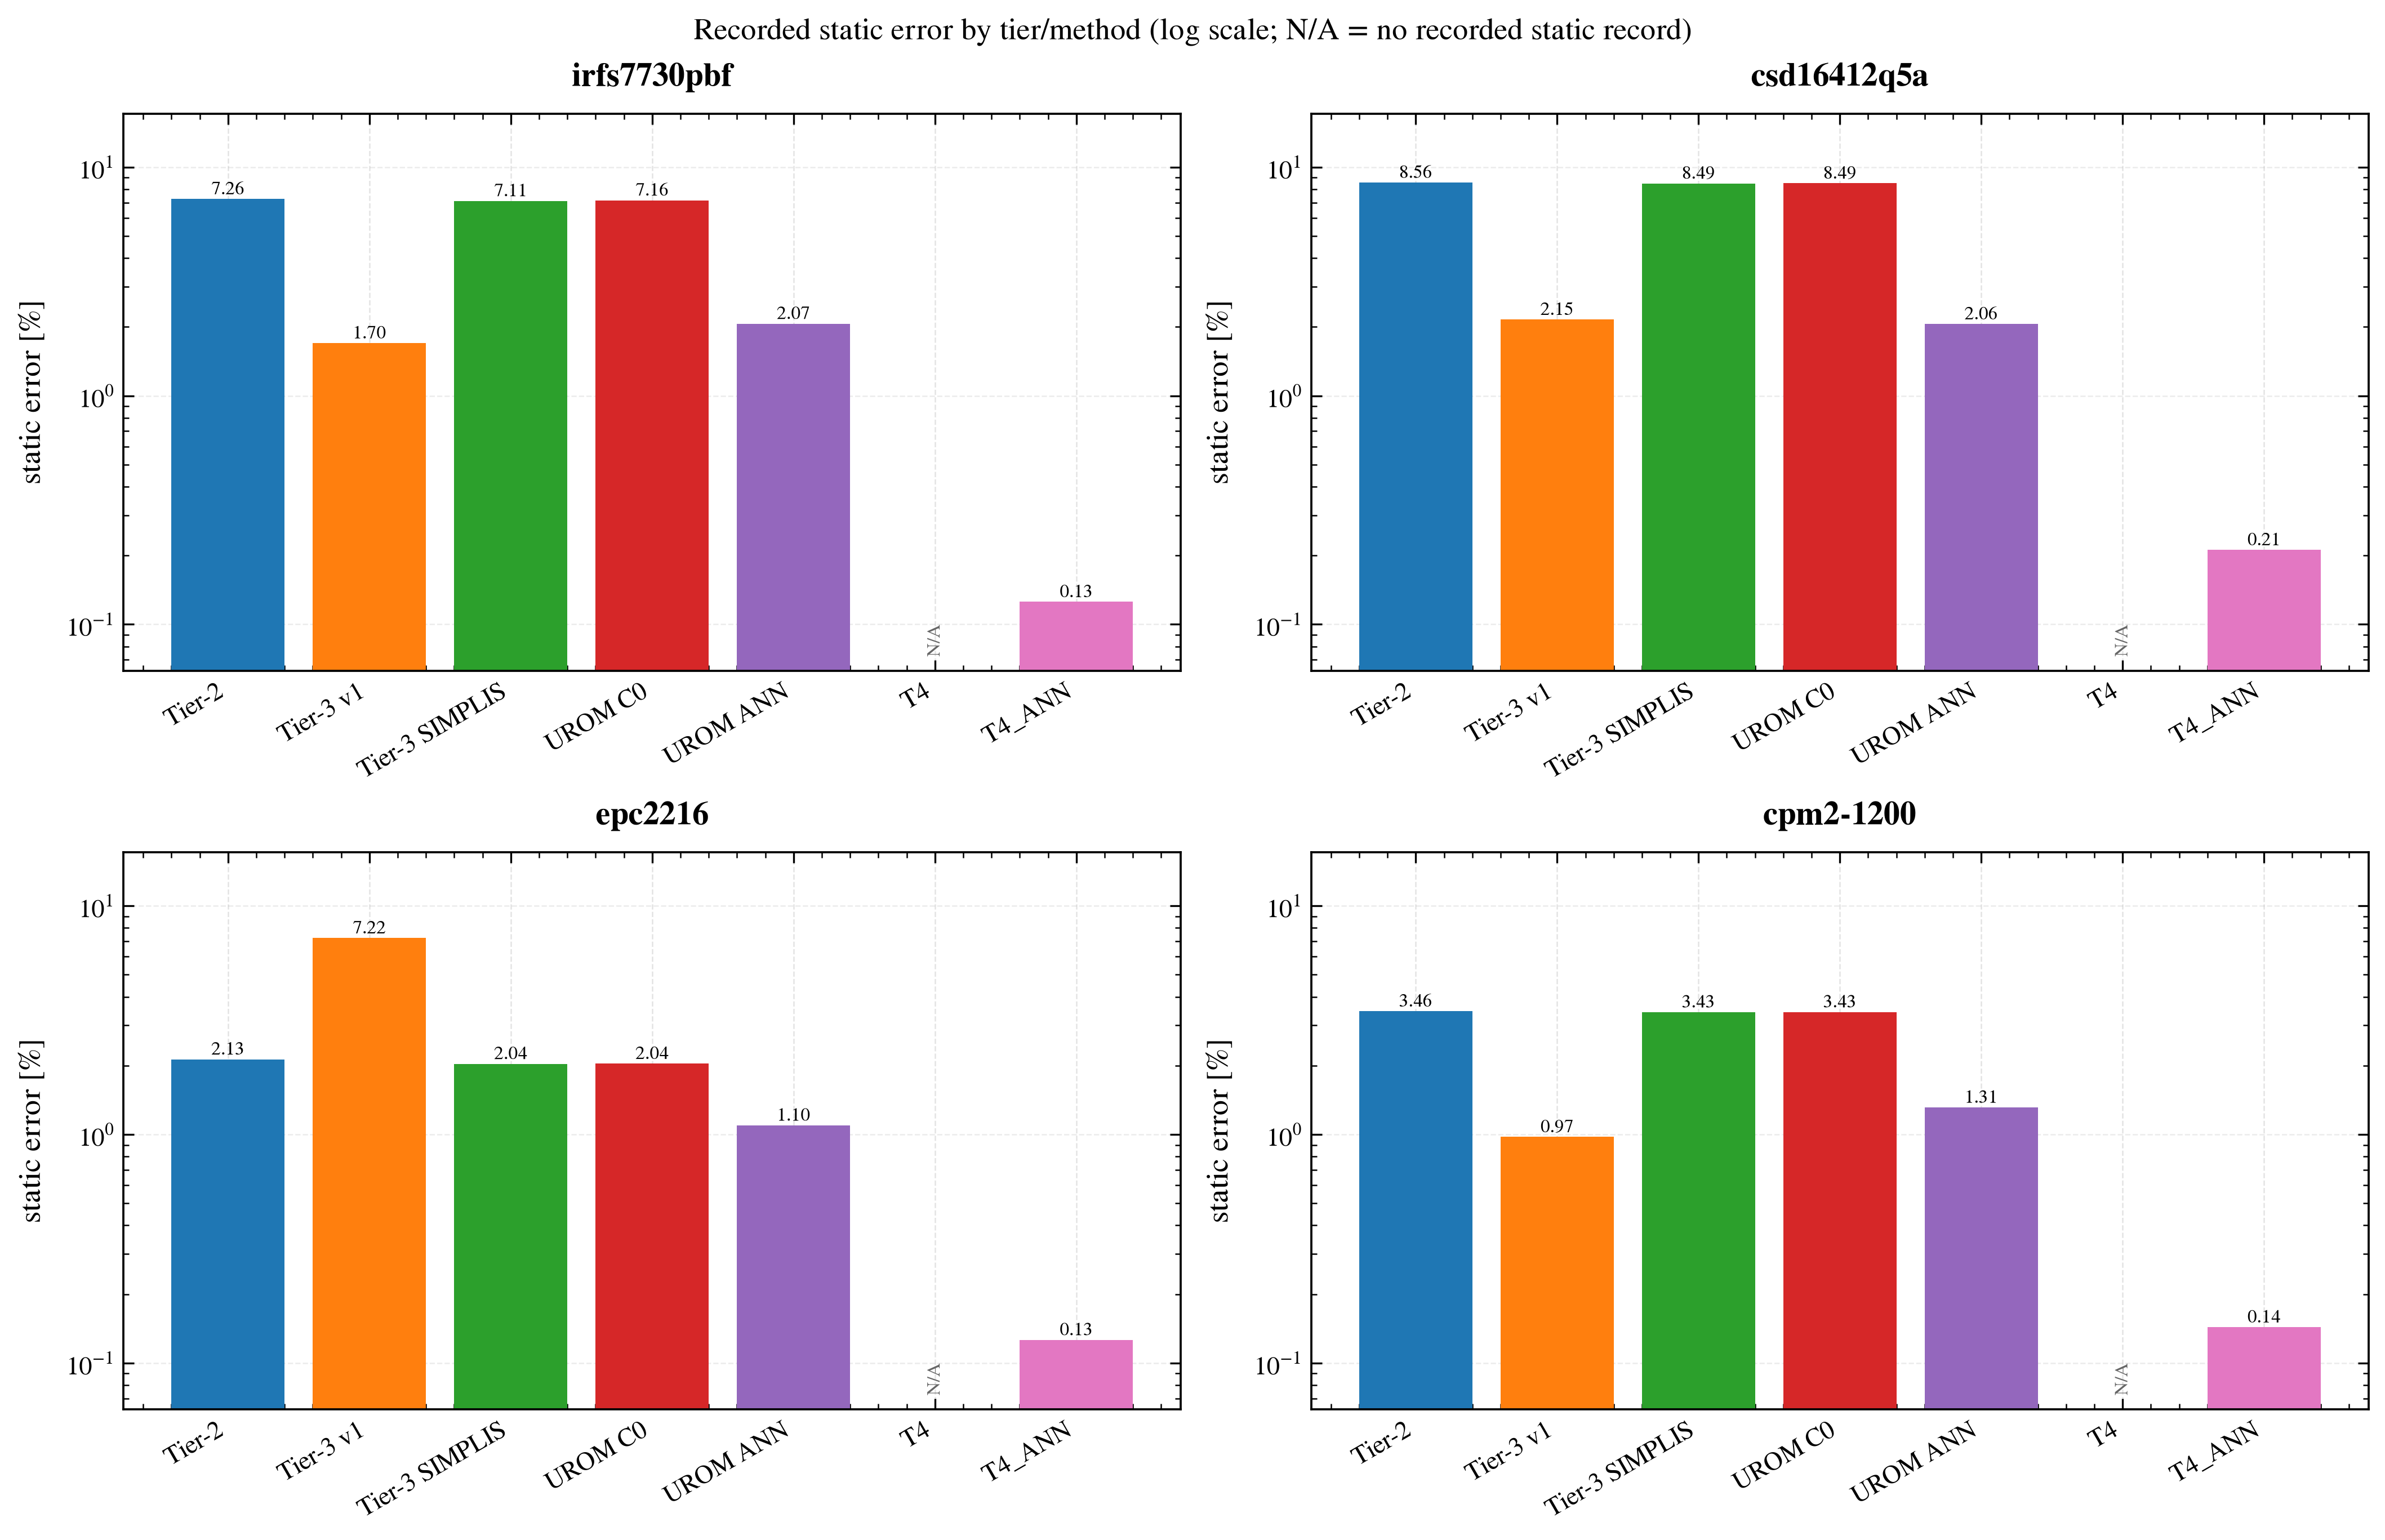

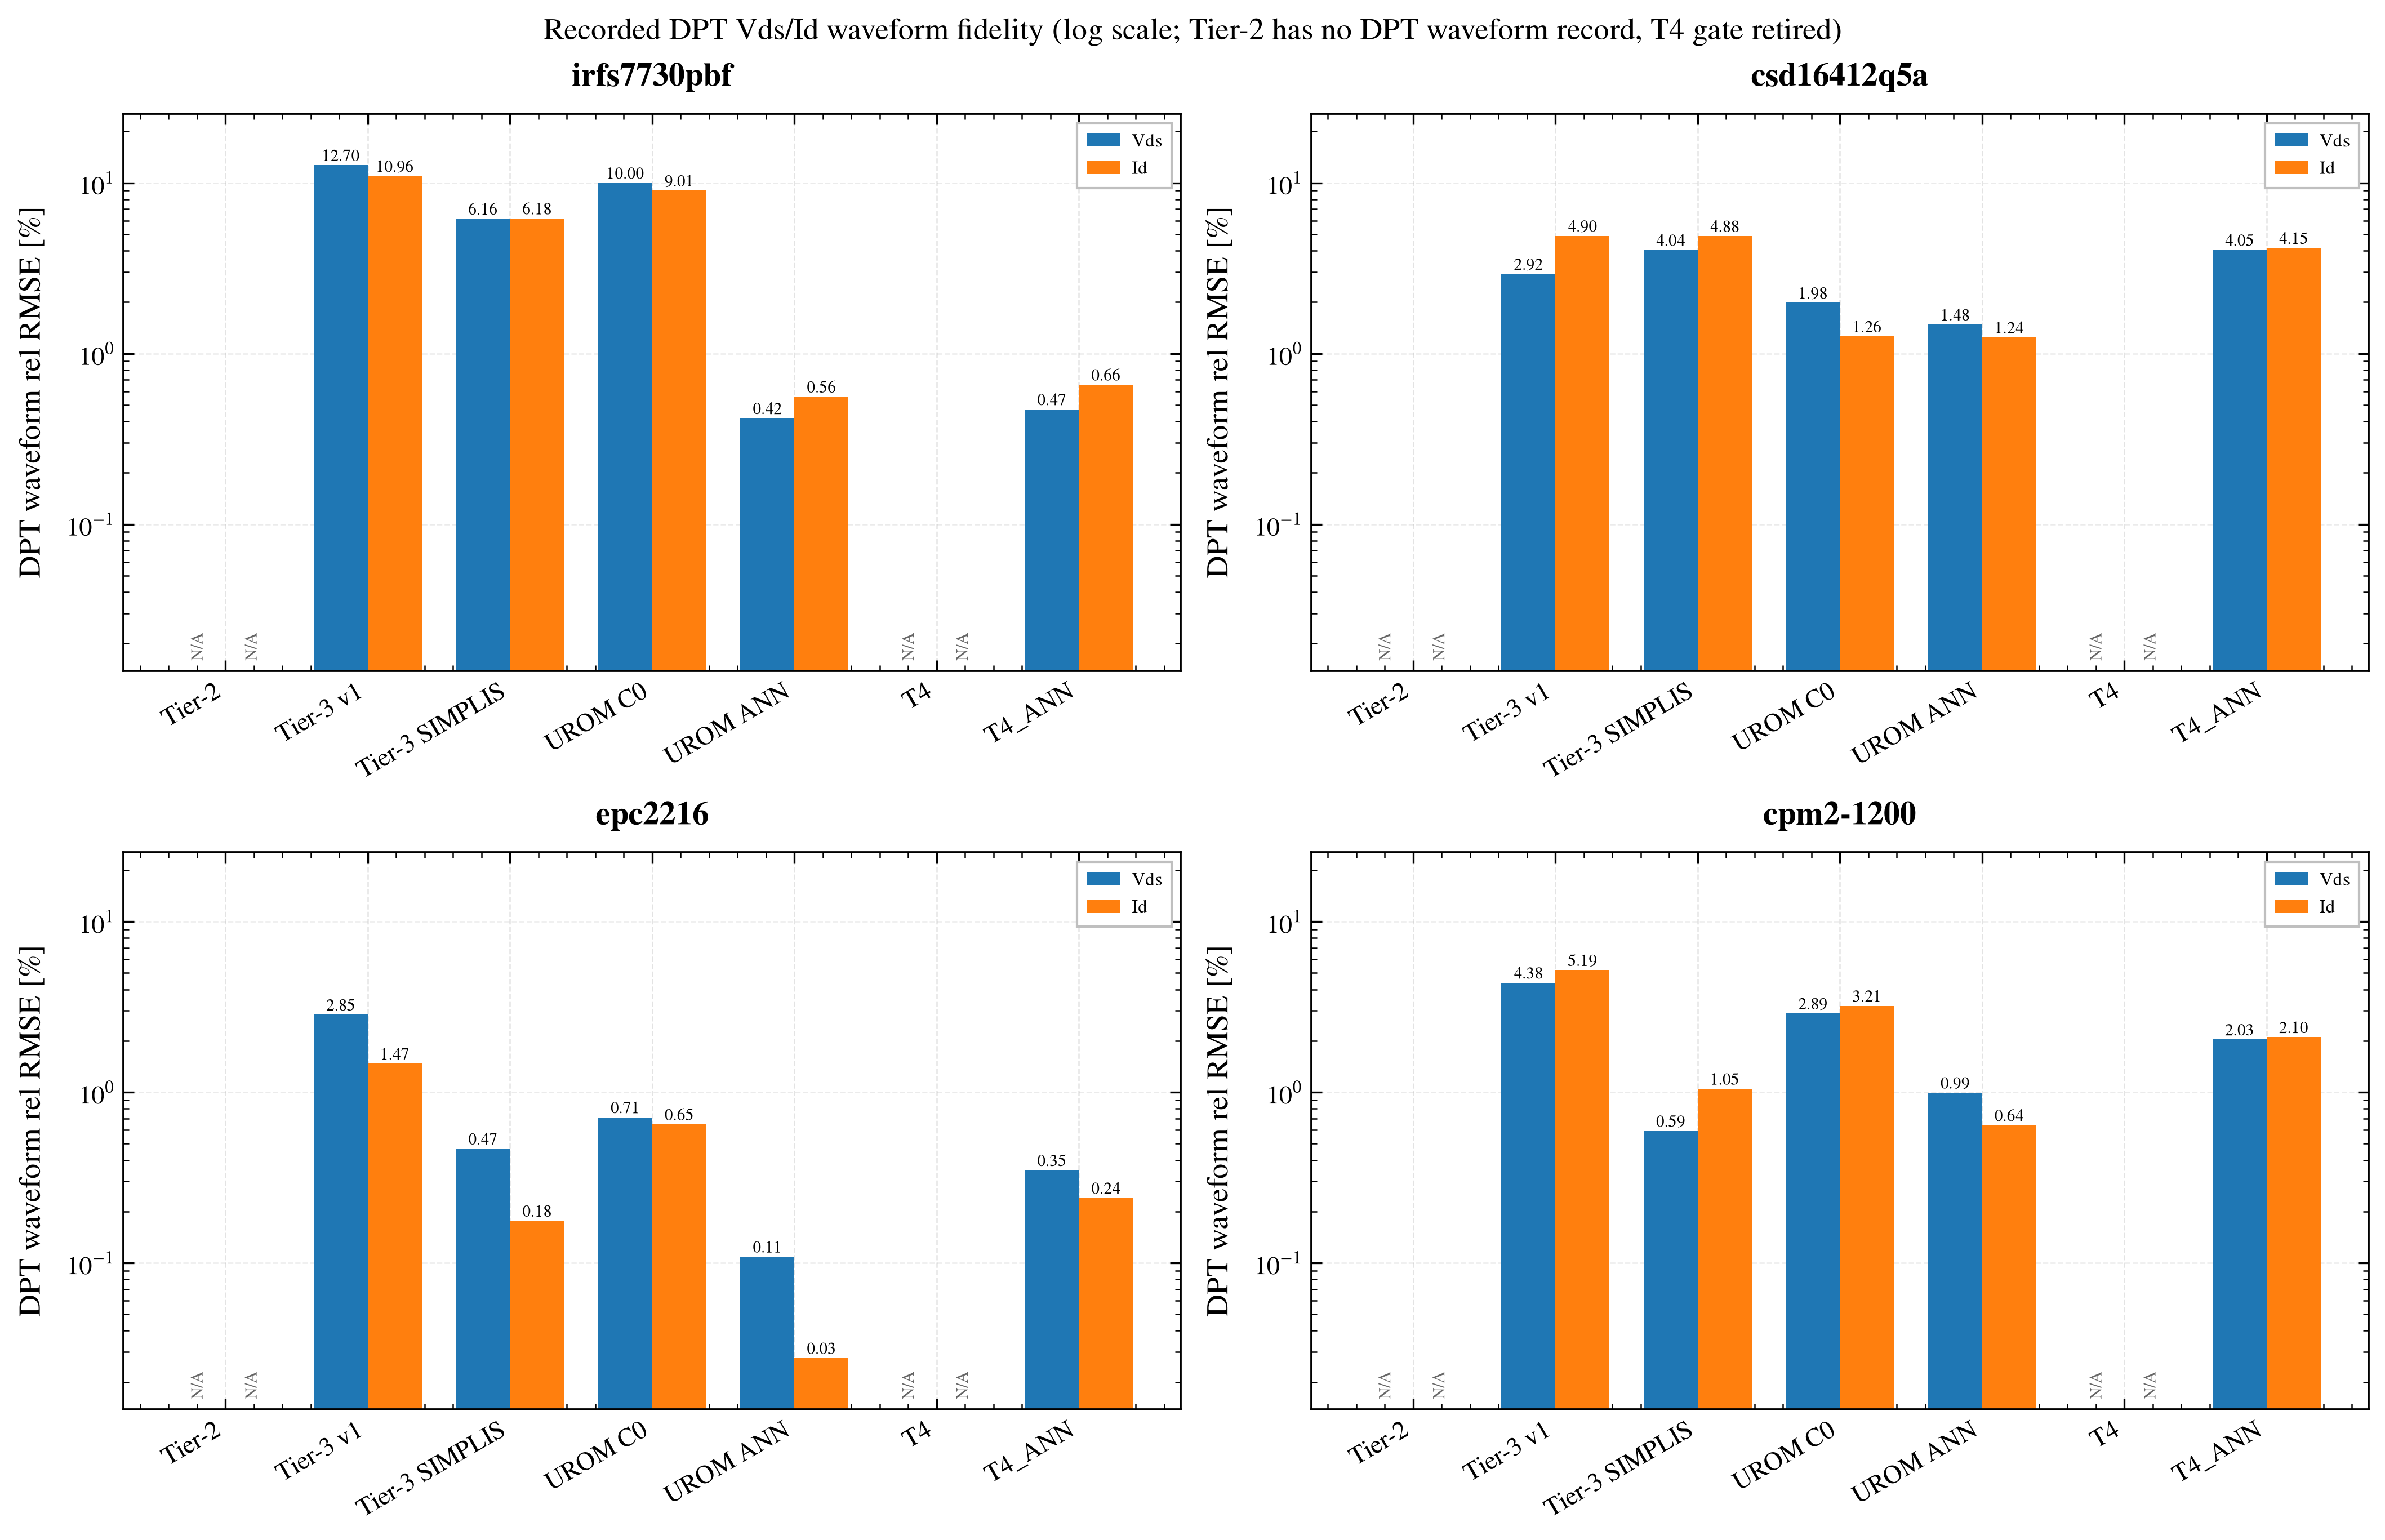

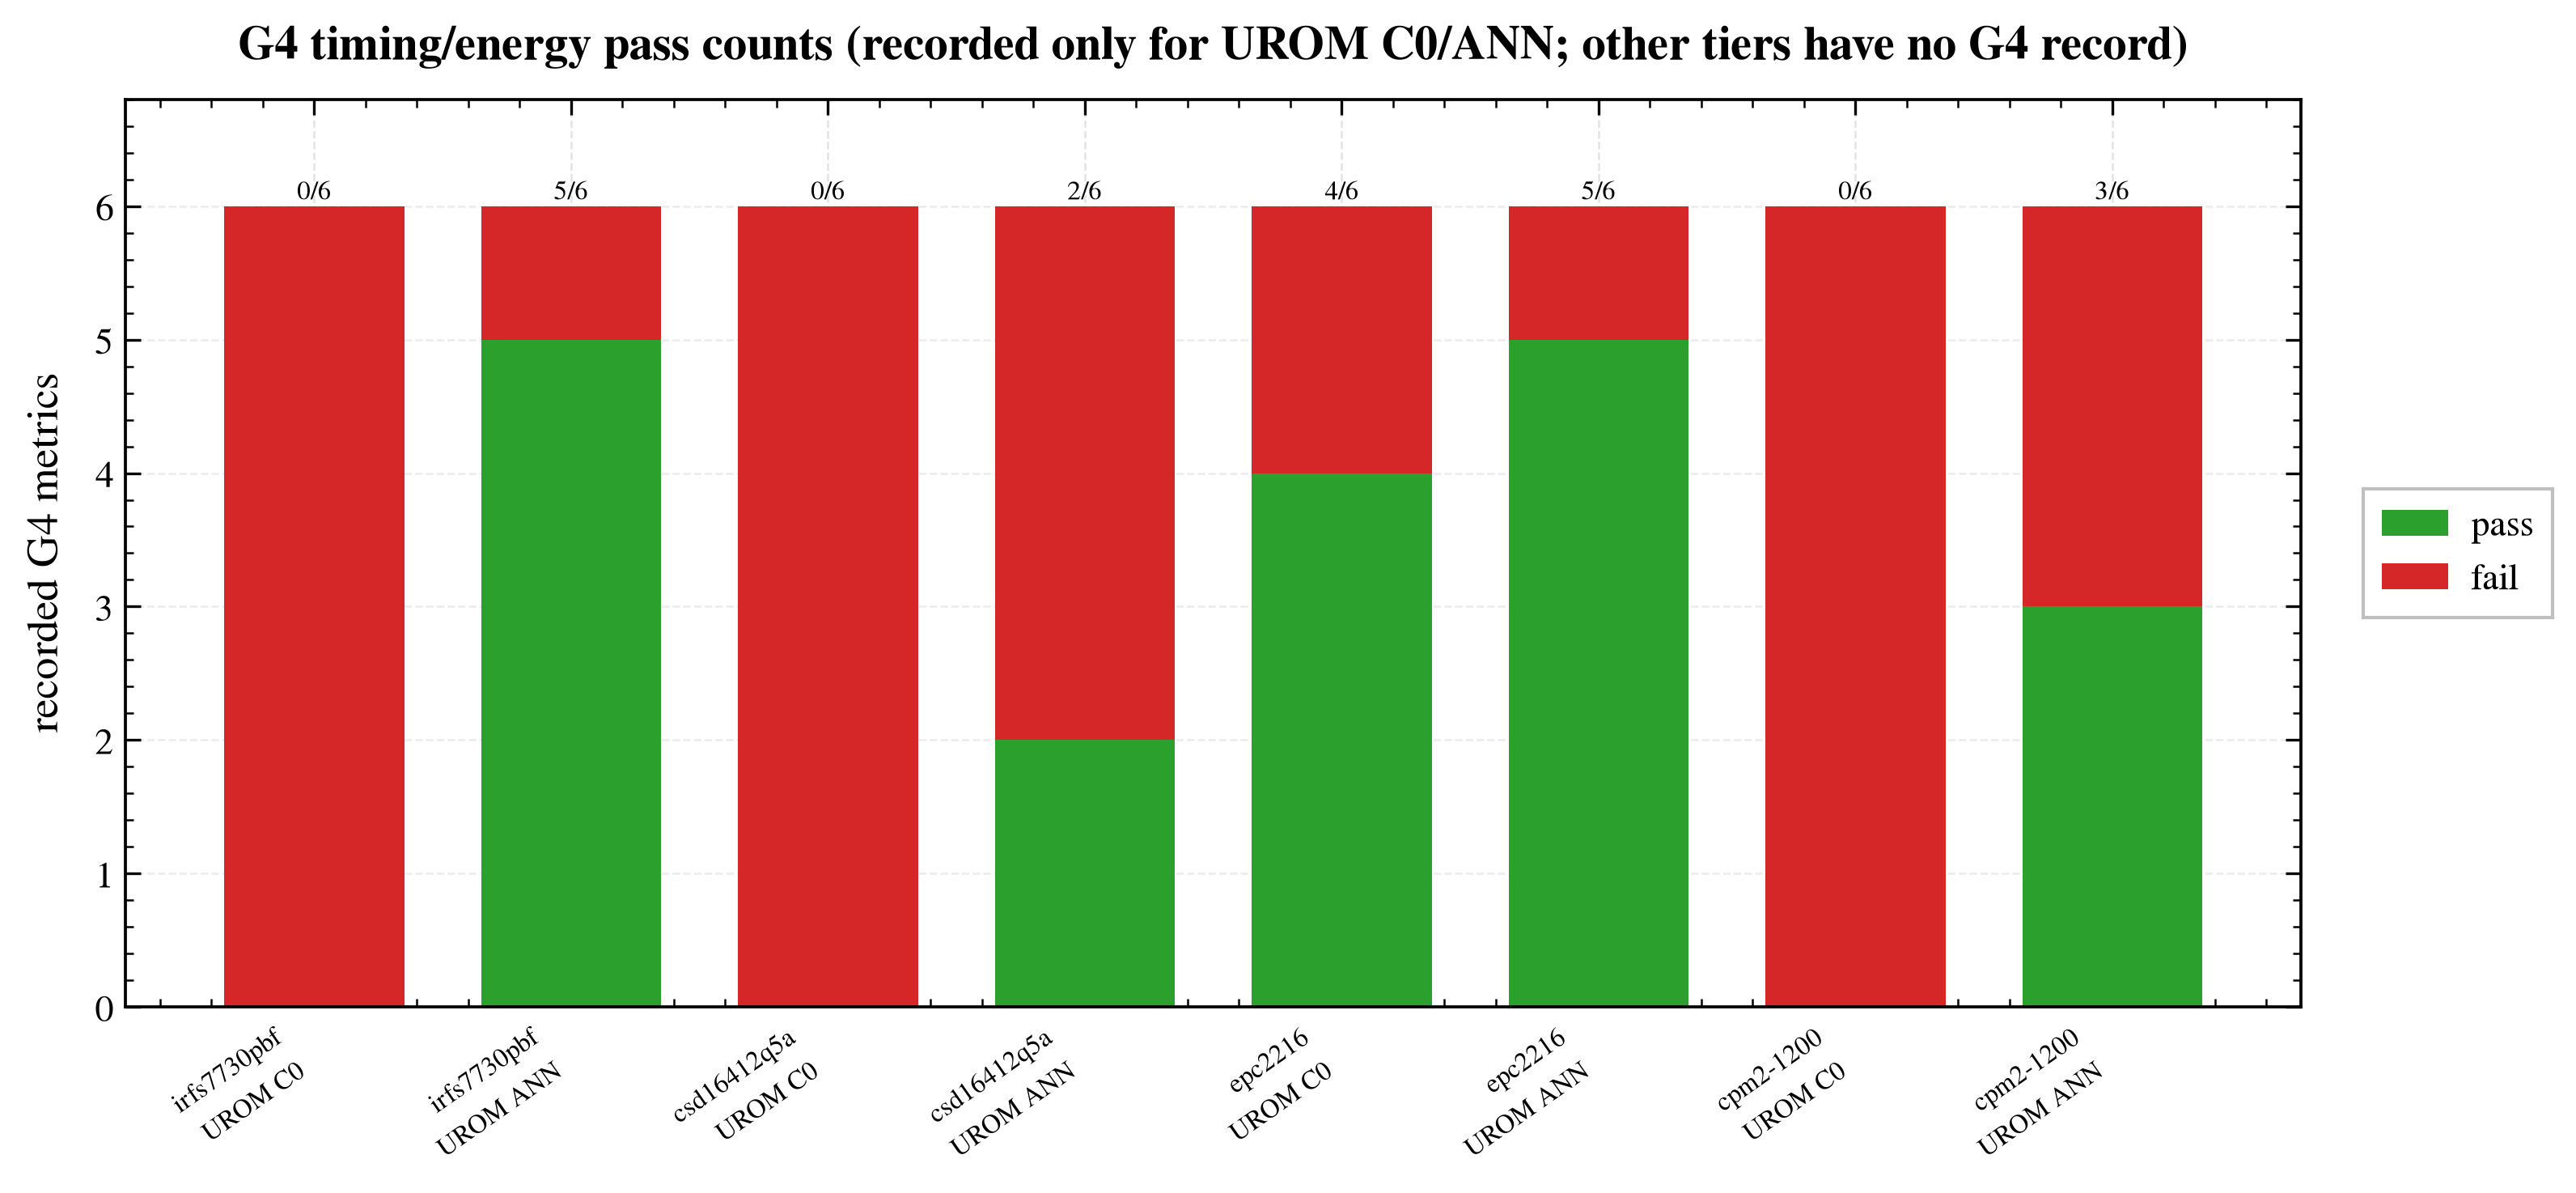

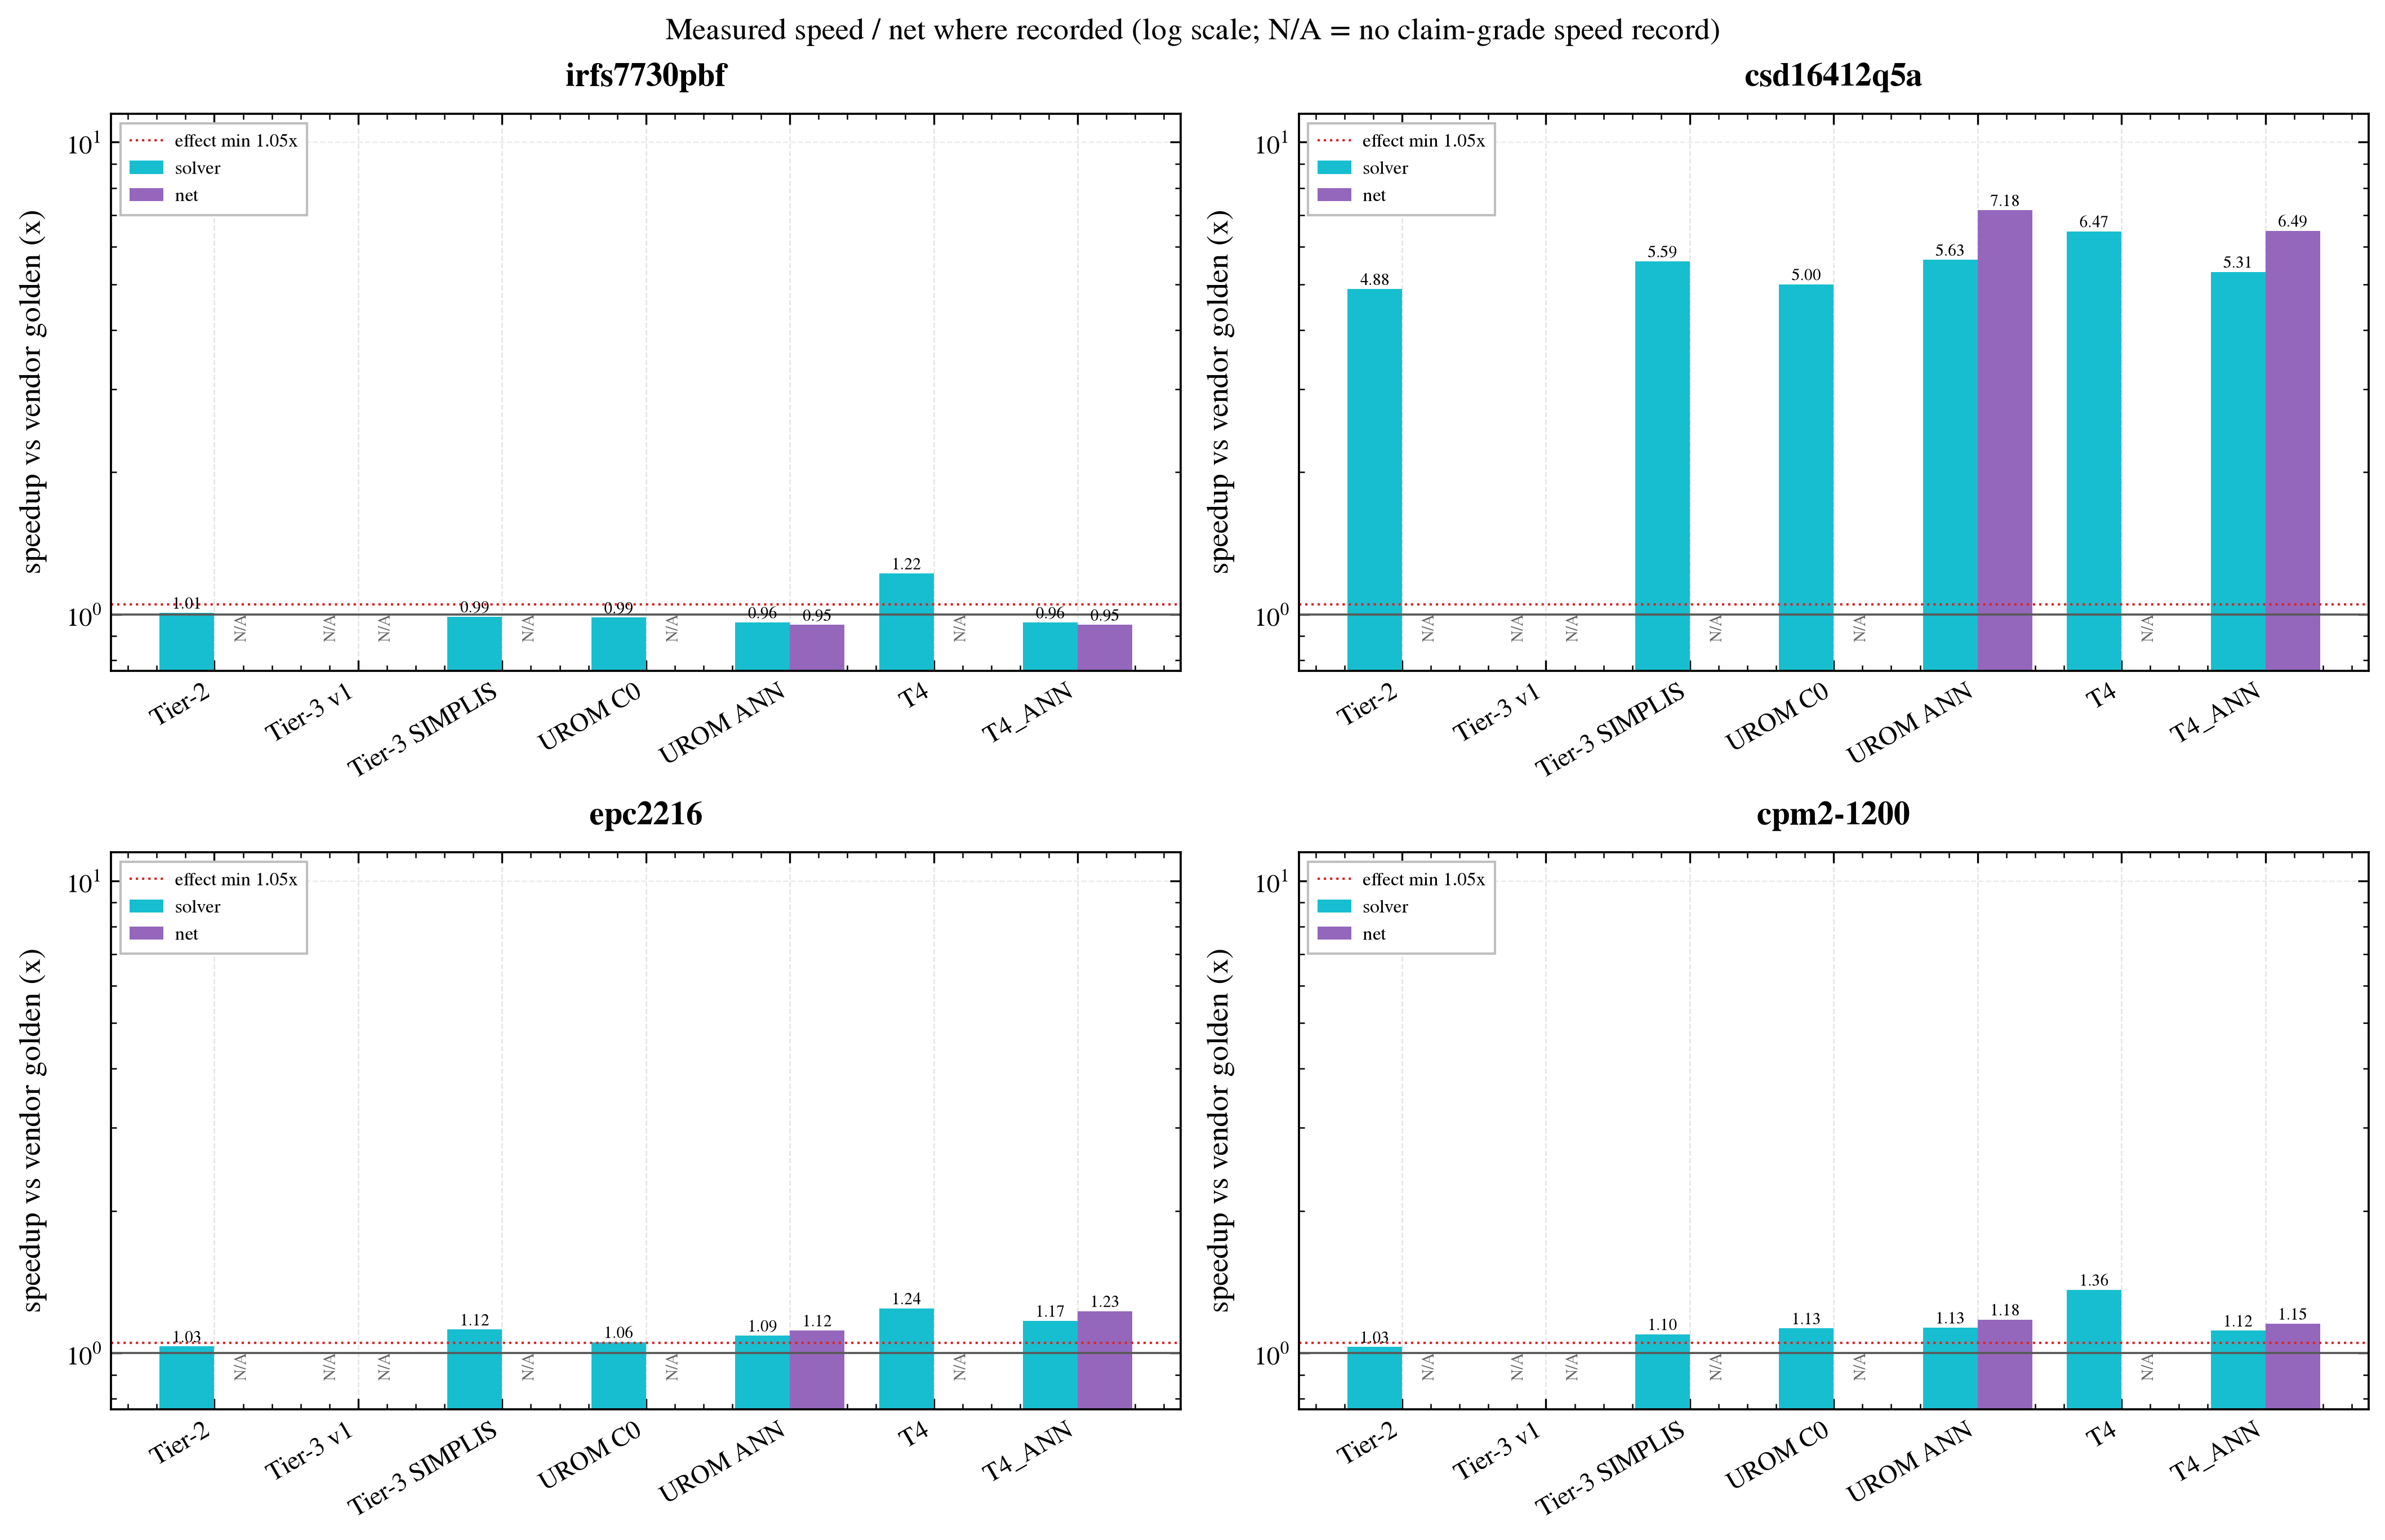

HTML report: C:\Users\GNKRISHNAN\Documents\GitHub\PieceSpice\reports\validation_report.html (846.3 KiB)


In [4]:
# --- Consolidated measured table -------------------------------------------
display_cols = ['vendor', 'method', 'static_rel_rmse_pct',
                'dpt_vds_rmse_pct', 'dpt_id_rmse_pct', 'g4_pass_n',
                'g4_total_n', 'speed_solver', 'speed_net', 'speed_basis']
summary_view = summary[display_cols].copy()
summary_view['g4'] = [
    f'{int(p)}/{int(t)}' if pd.notna(p) and pd.notna(t) else 'not available'
    for p, t in zip(summary['g4_pass_n'], summary['g4_total_n'])]
summary_view = summary_view.drop(columns=['g4_pass_n', 'g4_total_n'])
summary_view = summary_view.rename(columns={
    'static_rel_rmse_pct': 'static error [%]',
    'dpt_vds_rmse_pct': 'DPT Vds RMSE [%]',
    'dpt_id_rmse_pct': 'DPT Id RMSE [%]',
    'speed_solver': 'solver speedup',
    'speed_net': 'net speedup'})
summary_view['static error [%]'] = summary_view['static error [%]'].map(fnum)
summary_view['DPT Vds RMSE [%]'] = summary_view['DPT Vds RMSE [%]'].map(fnum)
summary_view['DPT Id RMSE [%]'] = summary_view['DPT Id RMSE [%]'].map(fnum)
summary_view['solver speedup'] = summary_view['solver speedup'].map(fnum)
summary_view['net speedup'] = summary_view['net speedup'].map(fnum)
print('Consolidated measured validation summary (all tiers/methods with records)')
display(summary_view.style.set_properties(**{'font-size': '9pt'}))

# --- Plot 1: recorded static fidelity -------------------------------------
fig_static, axs = plt.subplots(2, 2, figsize=(14.0, 9.0),
                               layout='constrained')
static_vals = summary['static_rel_rmse_pct'].dropna()
ymin = max(0.02, float(static_vals.min()) * 0.5)
ymax = float(static_vals.max()) * 2.0
for ax, vendor in zip(axs.flat, VENDORS):
    d = summary[summary['vendor'] == vendor].set_index('method').reindex(METHODS)
    vals = d['static_rel_rmse_pct'].astype(float).to_numpy()
    x = np.arange(len(METHODS))
    ax.bar(x, np.nan_to_num(vals, nan=0.0),
           color=[METHOD_COLORS[m] for m in METHODS], width=0.8)
    ax.set_yscale('log')
    ax.set_ylim(ymin, ymax)
    ax.set_xticks(x, METHODS, rotation=30, ha='right')
    ax.set_ylabel('static error [%]')
    ax.set_title(vendor)
    ax.grid(True, axis='y', alpha=0.25)
    for xi, v in zip(x, vals):
        if np.isfinite(v):
            ax.annotate(f'{v:.2f}', (xi, v), ha='center', va='bottom',
                        fontsize=8)
        else:
            ax.text(xi, ymin * 1.15, 'N/A', ha='center', va='bottom',
                    rotation=90, fontsize=8, color='0.4')
fig_static.suptitle('Recorded static error by tier/method (log scale; '
                    'N/A = no recorded static record)', fontsize=13)
plt.show()

# --- Plot 2: recorded DPT waveform fidelity -------------------------------
fig_dpt, axs = plt.subplots(2, 2, figsize=(14.0, 9.0),
                            layout='constrained')
dpt_all = summary[['dpt_vds_rmse_pct', 'dpt_id_rmse_pct']].to_numpy(dtype=float)
dpt_finite = dpt_all[np.isfinite(dpt_all)]
ymin_d = max(0.005, float(dpt_finite.min()) * 0.5)
ymax_d = float(dpt_finite.max()) * 2.0
x = np.arange(len(METHODS))
w = 0.38
for ax, vendor in zip(axs.flat, VENDORS):
    d = summary[summary['vendor'] == vendor].set_index('method').reindex(METHODS)
    vds = d['dpt_vds_rmse_pct'].astype(float).to_numpy()
    ids = d['dpt_id_rmse_pct'].astype(float).to_numpy()
    b1 = ax.bar(x - w / 2, np.nan_to_num(vds, nan=0.0), w,
                color='tab:blue', label='Vds')
    b2 = ax.bar(x + w / 2, np.nan_to_num(ids, nan=0.0), w,
                color='tab:orange', label='Id')
    ax.set_yscale('log')
    ax.set_ylim(ymin_d, ymax_d)
    ax.set_xticks(x, METHODS, rotation=30, ha='right')
    ax.set_ylabel('DPT waveform rel RMSE [%]')
    ax.set_title(vendor)
    ax.grid(True, axis='y', alpha=0.25)
    for bars, vals in ((b1, vds), (b2, ids)):
        for b, v in zip(bars, vals):
            if np.isfinite(v):
                ax.annotate(f'{v:.2f}', (b.get_x() + b.get_width() / 2, v),
                            ha='center', va='bottom', fontsize=7)
            else:
                ax.text(b.get_x() + b.get_width() / 2, ymin_d * 1.15, 'N/A',
                        ha='center', va='bottom', rotation=90,
                        fontsize=7, color='0.4')
    ax.legend(loc='upper right', fontsize=8)
fig_dpt.suptitle('Recorded DPT Vds/Id waveform fidelity (log scale; '
                 'Tier-2 has no DPT waveform record, T4 gate retired)',
                 fontsize=13)
plt.show()

# --- Plot 3: recorded G4 pass counts --------------------------------------
fig_g4, ax = plt.subplots(figsize=(10.5, 4.8), layout='constrained')
g4_methods = ['UROM C0', 'UROM ANN']
passes, fails, labels, totals = [], [], [], []
for vendor in VENDORS:
    for m in g4_methods:
        row = summary[(summary['vendor'] == vendor) &
                      (summary['method'] == m)].iloc[0]
        p, t = row['g4_pass_n'], row['g4_total_n']
        labels.append(f'{vendor}\n{m}')
        if pd.isna(p) or pd.isna(t):
            passes.append(0); fails.append(0); totals.append(None)
        else:
            passes.append(int(p)); fails.append(int(t) - int(p))
            totals.append(int(t))
xp = np.arange(len(labels))
ax.bar(xp, passes, 0.7, color='tab:green', label='pass')
ax.bar(xp, fails, 0.7, bottom=passes, color='tab:red', label='fail')
for xi, p, f, t in zip(xp, passes, fails, totals):
    ax.annotate(f'{p}/{t}' if t is not None else 'N/A',
                (xi, p + f), ha='center', va='bottom', fontsize=8)
ax.set_xticks(xp, labels, rotation=35, ha='right', fontsize=8)
ax.set_ylabel('recorded G4 metrics')
ax.set_ylim(0, 6.8)
ax.set_title('G4 timing/energy pass counts (recorded only for UROM C0/ANN; '
             'other tiers have no G4 record)')
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))
ax.grid(True, axis='y', alpha=0.25)
plt.show()

# --- Plot 4: measured speed / net -----------------------------------------
fig_speed, axs = plt.subplots(2, 2, figsize=(14.0, 9.0),
                              layout='constrained')
sp_vals = summary[['speed_solver', 'speed_net']].to_numpy(dtype=float)
sp_finite = sp_vals[np.isfinite(sp_vals)]
ymin_s = max(0.5, float(sp_finite.min()) * 0.8)
ymax_s = float(sp_finite.max()) * 1.6
for ax, vendor in zip(axs.flat, VENDORS):
    d = summary[summary['vendor'] == vendor].set_index('method').reindex(METHODS)
    solver = d['speed_solver'].astype(float).to_numpy()
    net = d['speed_net'].astype(float).to_numpy()
    b1 = ax.bar(x - w / 2, np.nan_to_num(solver, nan=0.0), w,
                color='tab:cyan', label='solver')
    b2 = ax.bar(x + w / 2, np.nan_to_num(net, nan=0.0), w,
                color='tab:purple', label='net')
    ax.set_yscale('log')
    ax.set_ylim(ymin_s, ymax_s)
    ax.axhline(1.0, color='0.35', lw=0.9)
    ax.axhline(1.05, color='tab:red', ls=':', lw=1.0,
               label='effect min 1.05x')
    ax.set_xticks(x, METHODS, rotation=30, ha='right')
    ax.set_ylabel('speedup vs vendor golden (x)')
    ax.set_title(vendor)
    ax.grid(True, axis='y', alpha=0.25)
    for bars, vals in ((b1, solver), (b2, net)):
        for b, v in zip(bars, vals):
            if np.isfinite(v):
                ax.annotate(f'{v:.2f}', (b.get_x() + b.get_width() / 2, v),
                            ha='center', va='bottom', fontsize=7)
            else:
                ax.text(b.get_x() + b.get_width() / 2, ymin_s * 1.15, 'N/A',
                        ha='center', va='bottom', rotation=90,
                        fontsize=7, color='0.4')
    ax.legend(loc='upper left', fontsize=8)
fig_speed.suptitle('Measured speed / net where recorded (log scale; N/A = '
                   'no claim-grade speed record)', fontsize=13)
plt.show()

# --- HTML report ----------------------------------------------------------
def fig_b64(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=140, bbox_inches='tight')
    return base64.b64encode(buf.getvalue()).decode('ascii')

fig_blocks = ''.join([
    '<h2>Measured summary plots</h2>',
    '<h3>Static fidelity</h3>',
    f'<img src="data:image/png;base64,{fig_b64(fig_static)}" style="max-width:100%"/>',
    '<h3>DPT Vds/Id waveform fidelity</h3>',
    f'<img src="data:image/png;base64,{fig_b64(fig_dpt)}" style="max-width:100%"/>',
    '<h3>G4 pass counts</h3>',
    f'<img src="data:image/png;base64,{fig_b64(fig_g4)}" style="max-width:100%"/>',
    '<h3>Measured speed / net</h3>',
    f'<img src="data:image/png;base64,{fig_b64(fig_speed)}" style="max-width:100%"/>',
])

html = (
    '<html><head><meta charset="utf-8">'
    '<title>PieceSpice Validation Report</title>'
    '<style>body{font-family:Arial,Helvetica,sans-serif;margin:24px;}'
    'table{border-collapse:collapse;margin:8px 0 18px;}'
    'td,th{border:1px solid #bbb;padding:4px 7px;font-size:12px;}'
    'th{background:#eee;}h2{margin-top:28px;}</style></head><body>'
    '<h1>PieceSpice Comprehensive Validation - measured JSON values</h1>'
    '<p>Coverage: Tier-2, Tier-3 v1, Tier-3 SIMPLIS, UROM C0, UROM ANN, '
    'T4 and T4_ANN. All values are read from the recorded JSON exports; '
    'no circuit is re-simulated by this report.</p>'
    + '<p><b>Static estimator note:</b> Tier-2 is the mean per-curve '
      'relative RMSE; Tier-3 v1/SIMPLIS and UROM use their emitted '
      'full-sweep relative RMSE; T4 has no static record; T4_ANN uses its '
      'ann_static_rms_rel. The summary column is labelled static error, not '
      'one common RMSE.</p>'
    + summary_view.to_html(index=False, escape=True)
    + fig_blocks
    + '<p>' + CAVEAT + '</p>'
    + ''.join(sections) + '</body></html>')
OUT_HTML.parent.mkdir(parents=True, exist_ok=True)
OUT_HTML.write_text(html, encoding='utf-8')
print(f'HTML report: {OUT_HTML.resolve()} ({OUT_HTML.stat().st_size / 1024:.1f} KiB)')
